Q1

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Words: ['renewable', 'energy', 'is', 'becoming', 'important', 'around', 'the', 'world', 'solar', 'panels', 'convert', 'sunlight', 'into', 'useful', 'electricity', 'wind', 'turbines', 'generate', 'power', 'without', 'burning', 'fuel', 'clean', 'energy', 'helps', 'reduce', 'pollution', 'and', 'protect', 'nature', 'many', 'communities', 'are', 'investing', 'in', 'sustainable', 'energy', 'sources', 'renewable', 'technology', 'can', 'support', 'a', 'healthier', 'future']
Sentences: ['renewable energy is becoming important around the world.', 'solar panels convert sunlight into useful electricity.', 'wind turbines generate power without burning fuel.', 'clean energy helps reduce pollution and protect nature.', 'many communities are investing in sustainable energy sources.', 'renewable technology can support a healthier future.']
Using split(): ['renewable', 'energy', 'is', 'becoming', 'important', 'around', 'the', 'world', 'solar', 'panels', 'convert', 'sunlight', 'into', 'useful', 'electric

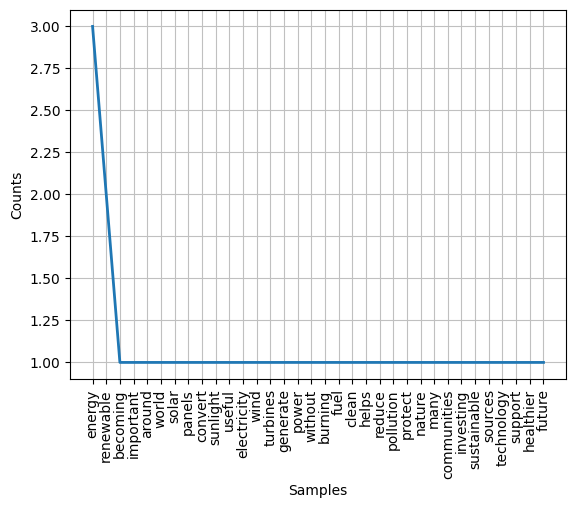

In [1]:
import re
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

original_text = """Renewable energy is becoming important around the world.
Solar panels convert sunlight into useful electricity.
Wind turbines generate power without burning fuel.
Clean energy helps reduce pollution and protect nature.
Many communities are investing in sustainable energy sources.
Renewable technology can support a healthier future."""

text = original_text.lower()
text = re.sub(r'[^\w\s]', '', text)

words = word_tokenize(text)
sentences = sent_tokenize(original_text.lower())

print("Words:", words)
print("Sentences:", sentences)

print("Using split():", text.split())
print("Using word_tokenize():", word_tokenize(text))
# split() only breaks on whitespace, so punctuation stays attached to words (for example, "world." stays as one token).
# word_tokenize() separates punctuation into its own tokens and handles contractions ("don't" becomes "do" and "n't").

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in words if word not in stop_words]

print("After removing stopwords:", filtered_words)

fdist = FreqDist(filtered_words)
print("Word frequency:", fdist)
print("Frequency list:", fdist.most_common())

fdist.plot()
plt.show()

Q2

In [2]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

words = re.findall(r'\b[a-zA-Z]+\b', text)

print("Words containing only alphabets:", words)

stop_words = set(stopwords.words('english'))
filtered_words = []

for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("After removing stopwords:", filtered_words)

ps = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = []
lemmatized_words = []

for word in filtered_words:
    stemmed_words.append(ps.stem(word))
    lemmatized_words.append(lemmatizer.lemmatize(word))

print("Stemmed words:", stemmed_words)
print("Lemmatized words:", lemmatized_words)

# Stemming chops suffixes by rules and can produce non-words, such as "renew" or "energi" in this example.
# Lemmatization uses a dictionary and tends to return recognizable base words, such as "source" or "community".
# Prefer stemming when speed matters and exact words don't, as in search or indexing.
# Prefer lemmatization when the output must be real words with correct meaning, as in chatbots and text analysis.

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Words containing only alphabets: ['renewable', 'energy', 'is', 'becoming', 'important', 'around', 'the', 'world', 'solar', 'panels', 'convert', 'sunlight', 'into', 'useful', 'electricity', 'wind', 'turbines', 'generate', 'power', 'without', 'burning', 'fuel', 'clean', 'energy', 'helps', 'reduce', 'pollution', 'and', 'protect', 'nature', 'many', 'communities', 'are', 'investing', 'in', 'sustainable', 'energy', 'sources', 'renewable', 'technology', 'can', 'support', 'a', 'healthier', 'future']
After removing stopwords: ['renewable', 'energy', 'becoming', 'important', 'around', 'world', 'solar', 'panels', 'convert', 'sunlight', 'useful', 'electricity', 'wind', 'turbines', 'generate', 'power', 'without', 'burning', 'fuel', 'clean', 'energy', 'helps', 'reduce', 'pollution', 'protect', 'nature', 'many', 'communities', 'investing', 'sustainable', 'energy', 'sources', 'renewable', 'technology', 'support', 'healthier', 'future']
Stemmed words: ['renew', 'energi', 'becom', 'import', 'around', 'w

Q3

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "This camera captures sharp photos in low light.",
    "The tablet has a bright screen and long battery life.",
    "This camera is lightweight and easy to carry."
]

cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words:")
print(cv.get_feature_names_out())
print(bow.toarray())

tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)

words = tfidf.get_feature_names_out()
scores = tfidf_matrix.toarray()

print("\nTF-IDF Scores:")
print(words)
print(scores)

print("\nTop 3 keywords from each text:")

for i in range(len(texts)):
    word_scores = list(zip(words, scores[i]))
    word_scores.sort(key=lambda x: x[1], reverse=True)

    print("\nText", i + 1, ":", texts[i])
    for word, score in word_scores[:3]:
        print(word, ":", round(score, 3))
# A high TF-IDF score means the word appears in that text but is rare in the others.
# Words shared across texts receive lower scores because they are less distinctive.
# The top keywords for each text highlight its most distinctive terms.

Bag of Words:
['and' 'battery' 'bright' 'camera' 'captures' 'carry' 'easy' 'has' 'in'
 'is' 'life' 'light' 'lightweight' 'long' 'low' 'photos' 'screen' 'sharp'
 'tablet' 'the' 'this' 'to']
[[0 0 0 1 1 0 0 0 1 0 0 1 0 0 1 1 0 1 0 0 1 0]
 [1 1 1 0 0 0 0 1 0 0 1 0 0 1 0 0 1 0 1 1 0 0]
 [1 0 0 1 0 1 1 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1]]

TF-IDF Scores:
['battery' 'bright' 'camera' 'captures' 'carry' 'easy' 'life' 'light'
 'lightweight' 'long' 'low' 'photos' 'screen' 'sharp' 'tablet']
[[0.         0.         0.32200242 0.42339448 0.         0.
  0.         0.42339448 0.         0.         0.42339448 0.42339448
  0.         0.42339448 0.        ]
 [0.40824829 0.40824829 0.         0.         0.         0.
  0.40824829 0.         0.         0.40824829 0.         0.
  0.40824829 0.         0.40824829]
 [0.         0.         0.40204024 0.         0.52863461 0.52863461
  0.         0.         0.52863461 0.         0.         0.
  0.         0.         0.        ]]

Top 3 keywords from each text:

T

Q4

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

nltk.download('stopwords')

text1 = """Electric vehicles run on electric motors instead of petrol engines.
They store energy in rechargeable batteries.
Electric vehicles can reduce tailpipe pollution.
Charging stations help drivers recharge their vehicles."""

text2 = """Cloud computing provides services over the internet.
Users can store files on remote servers.
Cloud platforms help teams access applications from different places.
Businesses use cloud computing to scale their services."""

stop_words = set(stopwords.words('english'))

words1 = re.findall(r'\b[a-zA-Z]+\b', text1.lower())
words2 = re.findall(r'\b[a-zA-Z]+\b', text2.lower())

words1 = [word for word in words1 if word not in stop_words]
words2 = [word for word in words2 if word not in stop_words]

print("Text 1 tokens:", words1)
print("Text 2 tokens:", words2)

set1 = set(words1)
set2 = set(words2)

jaccard = len(set1.intersection(set2)) / len(set1.union(set2))

print("Jaccard Similarity:", jaccard)

texts = [text1, text2]

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print("Cosine Similarity:", cosine[0][0])
# Jaccard counts shared unique words and ignores how often they appear.
# Cosine similarity uses TF-IDF weights to compare the texts' word patterns.
# Cosine can be more informative when the importance of individual words matters.

Text 1 tokens: ['electric', 'vehicles', 'run', 'electric', 'motors', 'instead', 'petrol', 'engines', 'store', 'energy', 'rechargeable', 'batteries', 'electric', 'vehicles', 'reduce', 'tailpipe', 'pollution', 'charging', 'stations', 'help', 'drivers', 'recharge', 'vehicles']
Text 2 tokens: ['cloud', 'computing', 'provides', 'services', 'internet', 'users', 'store', 'files', 'remote', 'servers', 'cloud', 'platforms', 'help', 'teams', 'access', 'applications', 'different', 'places', 'businesses', 'use', 'cloud', 'computing', 'scale', 'services']
Jaccard Similarity: 0.05405405405405406
Cosine Similarity: 0.03021562144420873


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q5

Review: The headphones deliver clear sound and feel comfortable.
Polarity: 0.3
Subjectivity: 0.5277777777777778
Sentiment: Positive

Review: The service was quick and the staff were helpful.
Polarity: 0.3333333333333333
Subjectivity: 0.5
Sentiment: Positive

Review: I am pleased with the sturdy design and reliable performance.
Polarity: 0.5
Subjectivity: 1.0
Sentiment: Positive

Review: The headphones stopped working and the sound is awful.
Polarity: -0.3
Subjectivity: 0.7
Sentiment: Negative

Review: The delivery was late and the packaging was damaged.
Polarity: -0.3
Subjectivity: 0.6
Sentiment: Negative

Review: The product is average and does what it claims.
Polarity: -0.15
Subjectivity: 0.39999999999999997
Sentiment: Negative



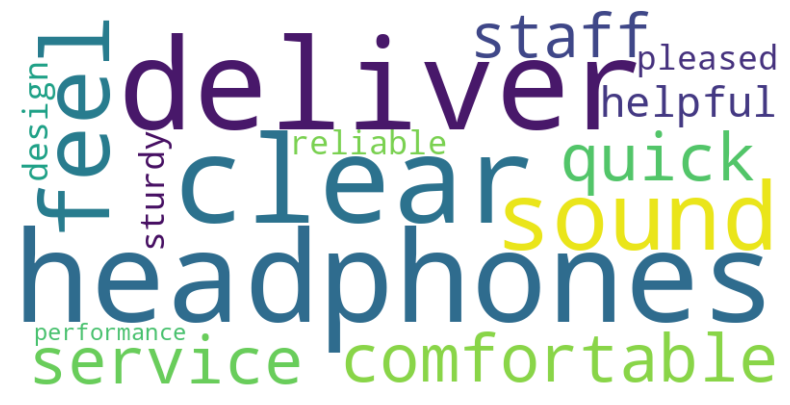

In [5]:
import nltk
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The headphones deliver clear sound and feel comfortable.",
    "The service was quick and the staff were helpful.",
    "I am pleased with the sturdy design and reliable performance.",
    "The headphones stopped working and the sound is awful.",
    "The delivery was late and the packaging was damaged.",
    "The product is average and does what it claims."
]

positive_reviews = []

for review in reviews:
    analysis = TextBlob(review)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)
    print()

positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(width=800, height=400, background_color="white")
wordcloud.generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Q6

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

text = """gardening is a relaxing activity for many people
plants need sunlight and water to grow well
gardeners prepare the soil before planting seeds
flowers add color and beauty to outdoor spaces
vegetables grow best with regular care
healthy soil helps plants develop strong roots
gardeners remove weeds and protect young plants
compost adds nutrients to the garden soil
rainwater can be collected to water plants
gardening teaches patience and care for nature"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

sequences = []
for line in text.split("\n"):
    numbers = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(numbers) + 1):
        sequences.append(numbers[:i])

max_length = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_length)

X = sequences[:, :-1]
y = sequences[:, -1]

model = Sequential()
model.add(Embedding(total_words, 16))
model.add(LSTM(64))
model.add(Dense(total_words, activation="softmax"))

model.compile(loss="sparse_categorical_crossentropy", optimizer="adam")

model.fit(X, y, epochs=200, verbose=0)

def generate_text(seed, num_words):
    text_so_far = seed
    for _ in range(num_words):
        numbers = tokenizer.texts_to_sequences([text_so_far])[0]
        numbers = pad_sequences([numbers], maxlen=max_length - 1)
        prediction = model.predict(numbers, verbose=0)
        next_index = np.argmax(prediction)
        text_so_far = text_so_far + " " + tokenizer.index_word[next_index]
    return text_so_far

print(generate_text("gardening", 4))
print(generate_text("plants", 4))
print(generate_text("the", 4))

gardening is a relaxing activity
plants add color and beauty
the soil helps plants develop
